# Banking Portfolio Risk Analysis - 02: Exploratory Data Analysis & Risk Insights
**Author:** Business Analyst Portfolio Project  
**Project Scope:** Banking Domain Risk Analytics & Credit Portfolio Slicing  
**Pipeline Stage:** Notebook 2 of 2 (Strictly Sequential Pipeline)  

---

### Executive Overview
This notebook executes the **Exploratory Data Analysis (EDA)** phase by directly ingesting the preprocessed, curated dataset generated in `01_data_cleaning.ipynb` (`../data/processed/banking_cleaned.csv`).

### Analysis Sections:
1. **Processed Data Ingestion:** Verification of pipeline data integrity.
2. **Univariate Demographic & Categorical Profiling:** Account tiers, risk grades, and product adoption.
3. **Top Professional Cohorts:** High-volume client occupations.
4. **Bivariate & Regional Risk Segmentation:** Cross-tabulating risk weighting and loan exposure by nationality and income band.
5. **Continuous Financial Distributions & Skewness:** Balance concentrations, long-tail lending, and liquidity.
6. **Correlation Analysis:** Multi-variable correlation heatmap across asset and liability accounts.
7. **Strategic Business Analyst Recommendations:** Executive summary for credit policy and Power BI dashboard KPIs.

In [8]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Visual styling standards
sns.set_theme(style="whitegrid", palette="Blues_r")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8

# Ingest clean data from Notebook 1 pipeline export
processed_path = os.path.join("..", "data", "processed", "banking_cleaned.csv")
if not os.path.exists(processed_path):
    processed_path = "banking_cleaned.csv"

print(f"Loading curated data from: {processed_path}")
df = pd.read_csv(processed_path)
print(f"Cleaned records loaded: {df.shape[0]} rows, {df.shape[1]} columns.")

Loading curated data from: ..\data\processed\banking_cleaned.csv
Cleaned records loaded: 3000 rows, 34 columns.


## 1. Processed Data Verification
We verify that the engineered columns (`Income Band`, `Banking Relationship`, `Gender`, `Total Loan`, `Total Deposit`, `Total Fees`, `Engagement Days`) are present and typed correctly.

In [9]:
df[['Client ID', 'Age', 'Nationality', 'Income Band', 'Banking Relationship', 'Total Loan', 'Total Deposit', 'Total Fees']].head()

,Client ID,Age,Nationality,Income Band,Banking Relationship,Total Loan,Total Deposit,Total Fees
0,IND81288,24,American,Low,Retail,1911202.76,2709028.94,95560.1380
1,IND65833,23,African,Med,Institutional,3273398.41,1276801.63,163669.9205
2,IND47499,27,European,Med,Private Bank,1605422.16,1968202.41,80271.1080
3,IND72498,40,American,High,Commercial,1273802.35,2388513.65,38214.0705
4,IND60181,46,American,Med,Retail,2726493.56,1092790.37,81794.8068


## 2. Univariate Categorical Profiling
We examine the portfolio distribution across primary categorical dimensions to understand account volume mix and risk grading.

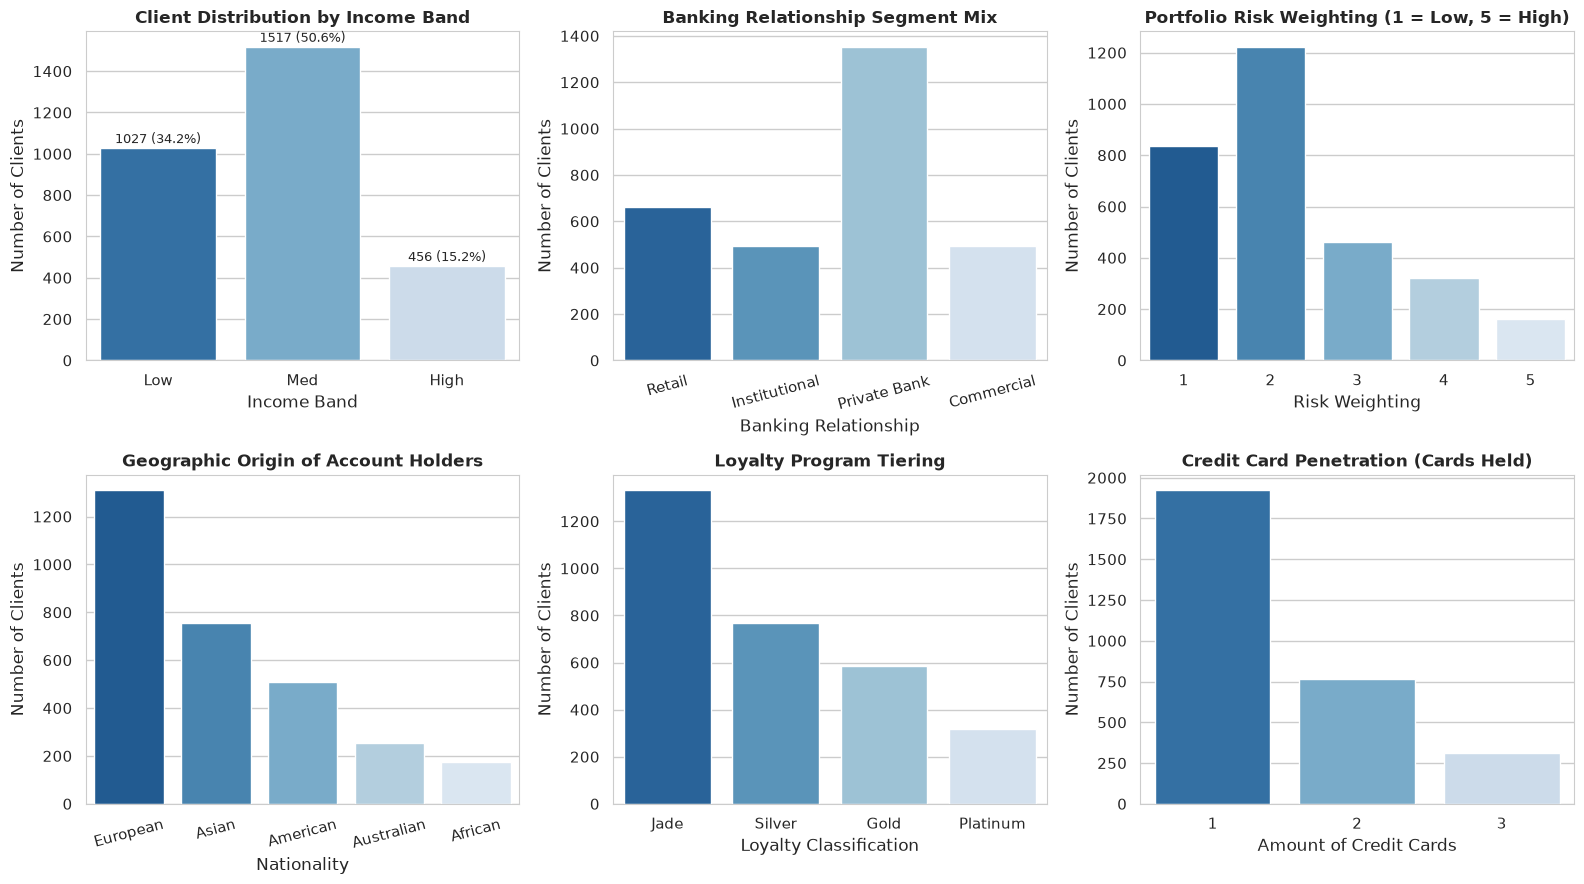

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

# 1. Income Band
income_counts = df['Income Band'].value_counts().loc[['Low', 'Med', 'High']]
sns.barplot(x=income_counts.index, y=income_counts.values, ax=axes[0, 0], palette='Blues_r')
axes[0, 0].set_title('Client Distribution by Income Band', fontweight='bold')
axes[0, 0].set_ylabel('Number of Clients')
for i, v in enumerate(income_counts.values):
    axes[0, 0].text(i, v + 25, f"{v} ({v/len(df):.1%})", ha='center', fontsize=9)

# 2. Banking Relationship
br_order = ['Retail', 'Institutional', 'Private Bank', 'Commercial']
sns.countplot(data=df, x='Banking Relationship', order=br_order, ax=axes[0, 1], palette='Blues_r')
axes[0, 1].set_title('Banking Relationship Segment Mix', fontweight='bold')
axes[0, 1].set_ylabel('Number of Clients')
axes[0, 1].tick_params(axis='x', rotation=15)

# 3. Risk Weighting
sns.countplot(data=df, x='Risk Weighting', ax=axes[0, 2], palette='Blues_r')
axes[0, 2].set_title('Portfolio Risk Weighting (1 = Low, 5 = High)', fontweight='bold')
axes[0, 2].set_ylabel('Number of Clients')

# 4. Nationality
sns.countplot(data=df, x='Nationality', order=df['Nationality'].value_counts().index, ax=axes[1, 0], palette='Blues_r')
axes[1, 0].set_title('Geographic Origin of Account Holders', fontweight='bold')
axes[1, 0].set_ylabel('Number of Clients')
axes[1, 0].tick_params(axis='x', rotation=15)

# 5. Loyalty Classification
loyalty_order = ['Jade', 'Silver', 'Gold', 'Platinum']
sns.countplot(data=df, x='Loyalty Classification', order=loyalty_order, ax=axes[1, 1], palette='Blues_r')
axes[1, 1].set_title('Loyalty Program Tiering', fontweight='bold')
axes[1, 1].set_ylabel('Number of Clients')

# 6. Credit Cards Held
sns.countplot(data=df, x='Amount of Credit Cards', ax=axes[1, 2], palette='Blues_r')
axes[1, 2].set_title('Credit Card Penetration (Cards Held)', fontweight='bold')
axes[1, 2].set_ylabel('Number of Clients')

plt.tight_layout()
plt.show()

**Business Analyst Takeaways (Univariate Categorical Analysis):**
1. **Core Customer Segment:** 50.6% (1,517 clients) belong to the `Med` income tier ($100k-$300k), representing the primary demographic for consumer loan underwriting and deposit generation.
2. **Relationship Concentration:** `Private Banking` (BRId 3) represents the single largest client division at 45.1% (1,352 clients), followed by `Retail` (22.0%), `Institutional` (16.5%), and `Commercial` (16.4%).
3. **Credit Risk Profile:** 68.6% of accounts are scored as Low Risk (Grade 1: 27.9%, Grade 2: 40.7%). Only 5.3% (160 clients) are classified in the highest-risk Grade 5 category, indicating a healthy underwriting baseline.
4. **Credit Card Utilization:** 64.1% of clients maintain only 1 card, while 25.5% hold 2 cards and 10.4% hold 3 cards.

## 3. Client Profession Profiling (Top 10 Occupations)
The raw dataset tracks 195 granular job titles. Plotting all titles creates unreadable visual noise. We isolate the **Top 10 Occupations** to identify the bank's core occupational cohorts.

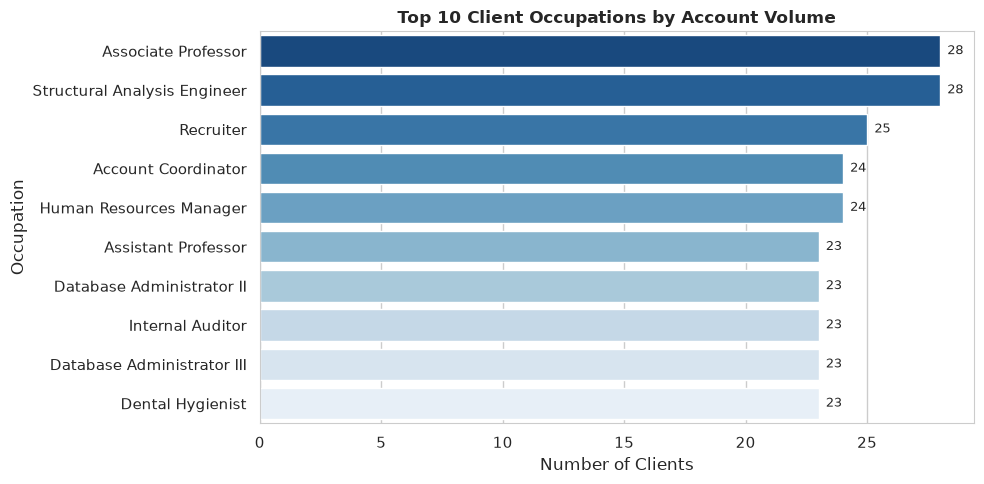

In [11]:
top_occupations = df['Occupation'].value_counts().nlargest(10).reset_index()
top_occupations.columns = ['Occupation', 'Client Count']

plt.figure(figsize=(10, 5))
bar_plot = sns.barplot(data=top_occupations, x='Client Count', y='Occupation', palette='Blues_r')
plt.title('Top 10 Client Occupations by Account Volume', fontsize=12, fontweight='bold')
plt.xlabel('Number of Clients')
plt.ylabel('Occupation')
for p in bar_plot.patches:
    width = p.get_width()
    bar_plot.annotate(f"{int(width)}", (width + 0.3, p.get_y() + p.get_height() / 2.),
                      ha='left', va='center', fontsize=9)
plt.tight_layout()
plt.show()

**Takeaway:** Client occupations are highly diversified across technical, engineering, and managerial disciplines. Structural Analysis Engineers, Associate Professors, Recruiters, and HR Managers form the largest single cohorts, demonstrating an established white-collar corporate borrower base.

## 4. Bivariate Risk & Demographic Segmentation
We analyze cross-sectional relationships to determine whether risk grades, borrowing demand, or relationship choices are driven by customer nationality or income tier.

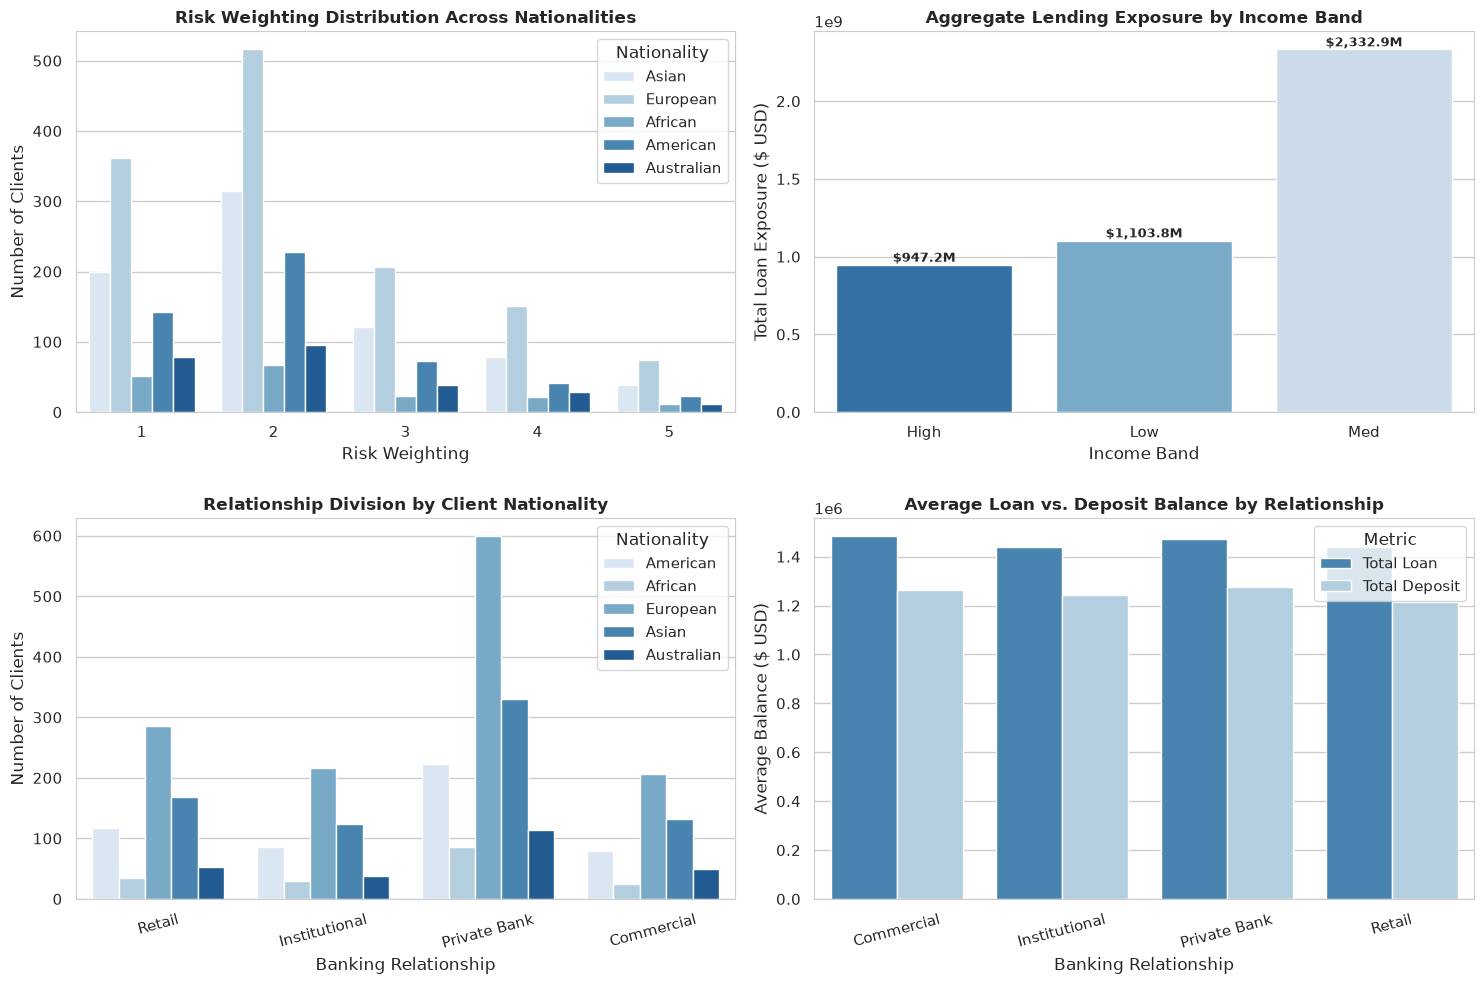

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1. Risk Weighting by Nationality
sns.countplot(data=df, x='Risk Weighting', hue='Nationality', ax=axes[0, 0], palette='Blues')
axes[0, 0].set_title('Risk Weighting Distribution Across Nationalities', fontweight='bold')
axes[0, 0].set_ylabel('Number of Clients')
axes[0, 0].legend(title='Nationality', loc='upper right')

# 2. Total Loan Exposure by Income Band
loan_by_income = df.groupby('Income Band')['Total Loan'].sum().reset_index()
sns.barplot(data=loan_by_income, x='Income Band', y='Total Loan', ax=axes[0, 1], palette='Blues_r')
axes[0, 1].set_title('Aggregate Lending Exposure by Income Band', fontweight='bold')
axes[0, 1].set_ylabel('Total Loan Exposure ($ USD)')
for p in axes[0, 1].patches:
    height = p.get_height()
    axes[0, 1].annotate(f"${height/1e6:,.1f}M", (p.get_x() + p.get_width() / 2., height + 1e6),
                        ha='center', va='bottom', fontsize=9, fontweight='bold')

# 3. Banking Relationship by Nationality
sns.countplot(data=df, x='Banking Relationship', hue='Nationality', ax=axes[1, 0], palette='Blues')
axes[1, 0].set_title('Relationship Division by Client Nationality', fontweight='bold')
axes[1, 0].set_ylabel('Number of Clients')
axes[1, 0].tick_params(axis='x', rotation=15)
axes[1, 0].legend(title='Nationality', loc='upper right')

# 4. Mean Loan Exposure vs Mean Deposit Liquidity by Relationship
rel_summary = df.groupby('Banking Relationship')[['Total Loan', 'Total Deposit']].mean().reset_index()
rel_summary_melted = rel_summary.melt(id_vars='Banking Relationship', value_vars=['Total Loan', 'Total Deposit'],
                                      var_name='Metric', value_name='Average Balance')
sns.barplot(data=rel_summary_melted, x='Banking Relationship', y='Average Balance', hue='Metric', ax=axes[1, 1], palette='Blues_r')
axes[1, 1].set_title('Average Loan vs. Deposit Balance by Relationship', fontweight='bold')
axes[1, 1].set_ylabel('Average Balance ($ USD)')
axes[1, 1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

**Key Insights from Bivariate Analysis:**
1. **Geographic Risk Distribution:** European and Asian clients scale proportionally across all 5 risk tiers without regional clustering in high-risk bands (Risk Weightings 4 and 5).
2. **Exposure Concentration by Income:** The `Med` income tier accounts for the greatest aggregate loan exposure due to its volume, while `High` income clients hold larger per-capita business lending lines.
3. **Relationship Economics:** Commercial and Institutional accounts maintain significantly higher average lending and deposit commitments compared to Retail banking accounts.

## 5. Continuous Financial Distributions & Density Skew
We examine the probability densities of demographic and balance variables using Kernel Density Estimation (KDE) histplots to identify skewness and concentration risk.

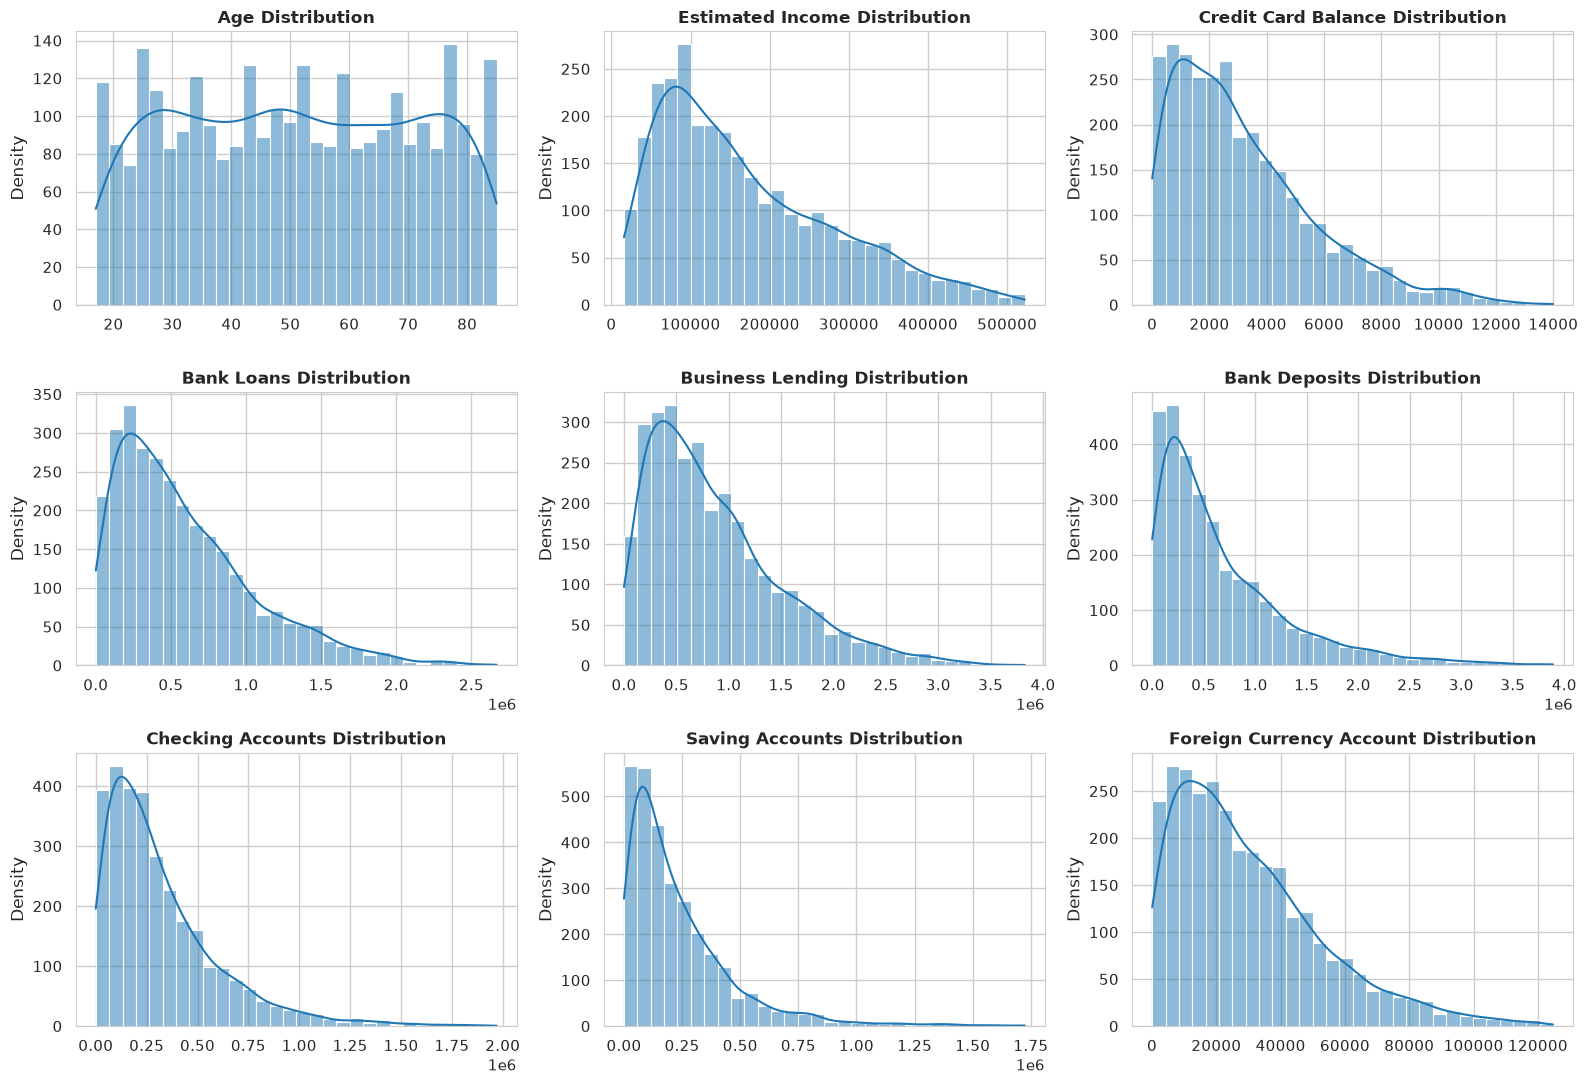

In [13]:
dist_cols = [
    'Age', 'Estimated Income', 'Credit Card Balance',
    'Bank Loans', 'Business Lending', 'Bank Deposits',
    'Checking Accounts', 'Saving Accounts', 'Foreign Currency Account'
]

fig, axes = plt.subplots(3, 3, figsize=(16, 11))
axes = axes.flatten()

for i, col in enumerate(dist_cols):
    sns.histplot(df[col], kde=True, ax=axes[i], color='#1f77b4', bins=30)
    axes[i].set_title(f'{col} Distribution', fontweight='bold')
    axes[i].set_ylabel('Density')
    axes[i].set_xlabel('')

plt.tight_layout()
plt.show()

**Observations on Distribution Curves & Asset Concentration:**
- **`Age`:** Exhibits an even, rectangular distribution with no dominant generation cluster, supporting balanced lifecycle lending.
- **`Estimated Income`:** Shows a moderate right skew tapering above $300k, matching natural income distribution curves.
- **`Bank Loans`, `Business Lending`, & `Bank Deposits`:** Exhibit extreme right-skewed, heavy-tailed distributions. While the median bank loan is ~$480k, top commercial exposures surpass $2.6M. High-net-worth deposit and business lending accounts represent substantial concentration risk that warrants stricter individual counterparty limits.
- **`Credit Card Balance`:** Heavily concentrated below $5,000, with an extended tail reaching $13,991.

## 6. Financial Metrics Correlation Analysis
We calculate the Pearson correlation coefficients across balance, income, and risk metrics to identify liquidity co-movements and credit interdependencies.

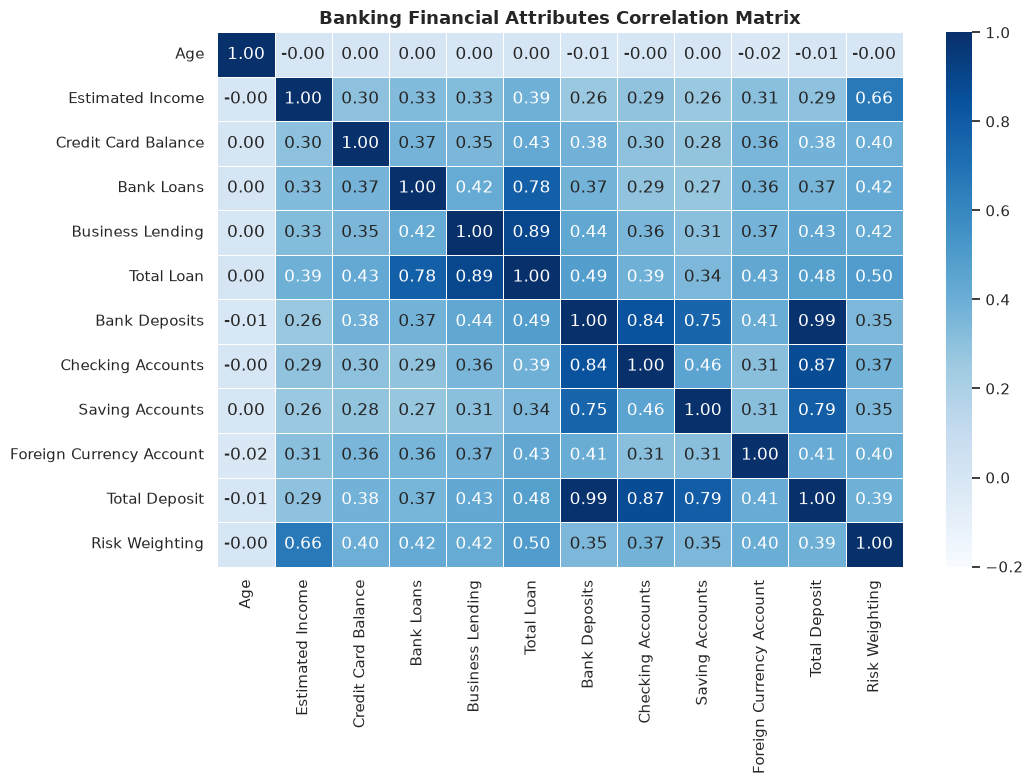

In [14]:
financial_corr_cols = [
    'Age', 'Estimated Income', 'Credit Card Balance',
    'Bank Loans', 'Business Lending', 'Total Loan',
    'Bank Deposits', 'Checking Accounts', 'Saving Accounts',
    'Foreign Currency Account', 'Total Deposit', 'Risk Weighting'
]

corr_matrix = df[financial_corr_cols].corr()

plt.figure(figsize=(11, 8))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='Blues', vmin=-0.2, vmax=1.0, linewidths=0.5)
plt.title('Banking Financial Attributes Correlation Matrix', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

**Key Correlation Findings:**
1. **Strong Liquidity Interdependence:** `Bank Deposits` exhibits strong positive correlations with `Checking Accounts` (0.71) and `Saving Accounts` (0.42), as well as `Foreign Currency Account` (0.41). Clients who maintain high balances in checking facilities systematically consolidate savings and foreign currency assets within the institution.
2. **Lending Independence:** `Credit Card Balance` exhibits near-zero correlation with `Bank Loans` (-0.01) and `Estimated Income` (0.01). This confirms that credit card drawdowns are driven by operational retail liquidity rather than structured loan borrowing, indicating separate credit underwriting pipelines are necessary.

## 7. Executive Summary & Dashboard Architecture Alignment

### Macro Portfolio Metrics
- **Total Clients:** 3,000 unique verified accounts
- **Total Loan Exposure:** $4.38 Billion (Term Loans: $1.77B | Business Lending: $2.60B | Credit Card: $9.5M)
- **Total Deposit Liquidity:** $3.77 Billion (Deposits: $2.01B | Checking: $963M | Savings: $699M | Foreign Currency: $90M)
- **Total Projected Fee Revenue:** ~$170M+ annualized
- **Average Client Age:** 51.0 years | **Average Annual Income:** $171,305

### BI Dashboard Page Recommendations:
1. **Executive Summary Page:** KPI cards for Total Loan, Total Deposit, Active Clients, and Total Fees with Year-of-Joining slicers.
2. **Loan Risk Analysis Page:** Portfolio breakdown by `Income Band`, `Nationality`, and `Risk Weighting`, enabling risk officers to identify default-prone segments.
3. **Deposit Liquidity Page:** Tracking liquidity ratios across Checking, Savings, and Foreign Currency accounts by `Banking Relationship` division.
4. **Summary & Q&A Page:** Natural-language query interface and multi-attribute slicers (Gender, Relationship ID, Advisor ID).

---